# Meramal Indeks Harga Pangan 22 Negara Sepuluh Tahun ke Depan

| | |
| --- | --- |
| **Kompetisi** | [Penyisihan Data Mining Adikara 2024](https://www.kaggle.com/competitions/data-mining-adikara) (Kaggle, Desember 2024) |
| **Tujuan** | Meramal `FoodPriceIndex` bulanan 22 negara untuk 2014–2023 dari data 1970–2013 (metrik SMAPE) |
| **Data** | 11.616 baris latih (22 negara × 528 bulan), 2.640 baris uji (22 negara × 120 bulan) |
| **Penulis** | Fauzan Ahsanudin Alfikri · [Kaggle: fauzan2](https://www.kaggle.com/fauzan2) |
| **Tanggal** | Disusun ulang November 2026 (notebook asli 2024 hilang) |
| **Lingkungan** | Dijalankan penuh di Kaggle (CPU), ±2 menit |

**Pertanyaan penelitian.** Dengan horizon sepanjang 10 tahun, apakah lebih baik meramal setiap negara sendiri-sendiri,
atau meminjam informasi dari negara lain?

**Ringkasan temuan.**
- Meminjam informasi dari negara lain adalah keputusan paling berpengaruh. Menyusutkan laju pertumbuhan tiap negara 75% ke arah median 22 negara menurunkan SMAPE backtest dari **10,30** (setiap negara sendiri) menjadi **6,07**.
- Model akhir, rata-rata dari tren gabungan tersebut dan damped trend + musiman, mencapai SMAPE backtest **5,63**, kurang dari setengah baseline nilai terakhir (**12,05**).
- Kenaikan harga pangan melambat tajam setelah 1980-an (median 9,9% per tahun di 1970-an, sekitar 2% sejak 1990-an), jadi data lama justru menyesatkan. Model hanya memakai 3 sampai 5 tahun terakhir.
- Error tumbuh hampir linear terhadap jarak ramalan: sekitar 1,4 di tahun pertama dan 10 di tahun kesepuluh. Di horizon 10 tahun, yang paling menentukan adalah **arah tren**, bukan detail musiman.

**Alur:** 1. Setup → 2. Memahami data → 3. EDA → 4. Preprocessing → 5. Desain validasi → 6. Baseline →
7. Model per negara → 8. Model gabungan lintas negara → 9. Evaluasi → 10. Ramalan akhir & submission → 11. Kesimpulan

## 1. Setup

Semua import, parameter, dan path ada di sel ini. Model peramalan dan backtest ada di `src/models/forecasters.py`
agar notebook fokus pada cerita dan hasil.

In [1]:
import os
import shutil
import sys
import time
import warnings
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Folder src/ ada di root proyek (lokal) atau di dataset Kaggle "adikara-2024-data-mining-src"
SRC_ROOT = Path.cwd().parent
for r, _, f in os.walk("/kaggle/input", followlinks=True):
    if Path(r).name == "models" and "forecasters.py" in f:
        pkg = Path(r).parent
        if pkg.name == "src":
            SRC_ROOT = pkg.parent
        else:  # isi dataset langsung di root: salin agar bisa diimpor sebagai paket `src`
            SRC_ROOT = Path("/tmp/project")
            shutil.copytree(pkg, SRC_ROOT / "src", dirs_exist_ok=True)
        break
sys.path.insert(0, str(SRC_ROOT))
from src.data.load_data import clean_panel, find_data_dir, load_raw, t_to_date, to_panel
from src.models.forecasters import (backtest, context, fc_damped, fc_damped_seasonal, fc_last, fc_mean12,
                                    log_growth, make_drift, make_ensemble, make_pooled_drift, smape)
from src.visualization.plots import PALETTE, pct_axis, ref_line, save_fig, set_style

# ── Parameter eksperimen
HORIZON = 120                    # 10 tahun × 12 bulan, sama dengan panjang data uji
ORIGINS = [1993, 1998, 2003]     # tahun terakhir data latih pada setiap backtest
POOL_WEIGHTS = [0.0, 0.25, 0.5, 0.75, 1.0]

# ── Path (relatif; di Kaggle otomatis menunjuk /kaggle/input dan /kaggle/working)
DATA_DIR = find_data_dir(local="../data/raw")
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("../reports")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")
set_style()
C1, C2, C3, CN = PALETTE["normal"], PALETTE["fraud"], PALETTE["accent"], PALETTE["neutral"]
T0 = time.time()
print("DATA_DIR:", DATA_DIR, "| OUT_DIR:", OUT_DIR)

DATA_DIR: /kaggle/input/datasets/fauzan2/adikara-2024-data-mining-data | OUT_DIR: /kaggle/working


## 2. Memahami data

Setiap baris adalah satu negara pada satu bulan: `Country`, `Year`, `Month`, dan target `FoodPriceIndex`
(indeks harga pangan, tanpa satuan). Data latih mencakup Januari 1970 sampai Desember 2013; data uji meminta
ramalan **Januari 2014 sampai Desember 2023** untuk 22 negara yang sama. Jadi ini bukan regresi biasa, melainkan
**peramalan deret waktu dengan horizon 120 bulan**.

In [2]:
raw = load_raw(DATA_DIR)
train, test, sample = raw["train"], raw["test"], raw["sample"]
summary = pd.DataFrame({
    "baris": [len(train), len(test)],
    "negara": [train.Country.nunique(), test.Country.nunique()],
    "periode": [f"{train.date.min():%b %Y} – {train.date.max():%b %Y}", f"{test.date.min():%b %Y} – {test.date.max():%b %Y}"],
    "bulan per negara": [train.groupby("Country").size().iloc[0], test.groupby("Country").size().iloc[0]],
}, index=["train", "test"])
summary.style.format({"baris": "{:,}"})

,baris,negara,periode,bulan per negara
train,"11,616",22,Jan 1970 – Dec 2013,528
test,"2,640",22,Jan 2014 – Dec 2023,120


In [3]:
panel_raw = to_panel(train)
print("Negara:", ", ".join(panel_raw.columns))
print("Negara di test yang tidak ada di train:", set(test.Country) - set(train.Country) or "tidak ada")

Negara: Austria, Canada, Denmark, Finland, France, Germany, Greece, Israel, Italy, Japan, Luxembourg, Mexico, Netherlands, Portugal, South Africa, Spain, Sweden, Switzerland, Taiwan, China, Turkey, United Kingdom, United States
Negara di test yang tidak ada di train: tidak ada


## 3. Exploratory Data Analysis

### 3.1 Nilai kosong dan nilai nol: apa artinya?

In [4]:
missing = pd.DataFrame({
    "NaN": panel_raw.isna().sum(),
    "nilai 0": (panel_raw == 0).sum(),
    "nilai 0 terakhir": [t_to_date([panel_raw.index[(panel_raw[c] == 0).values].max()])[0].strftime("%b %Y")
                         if (panel_raw[c] == 0).any() else "-" for c in panel_raw],
})

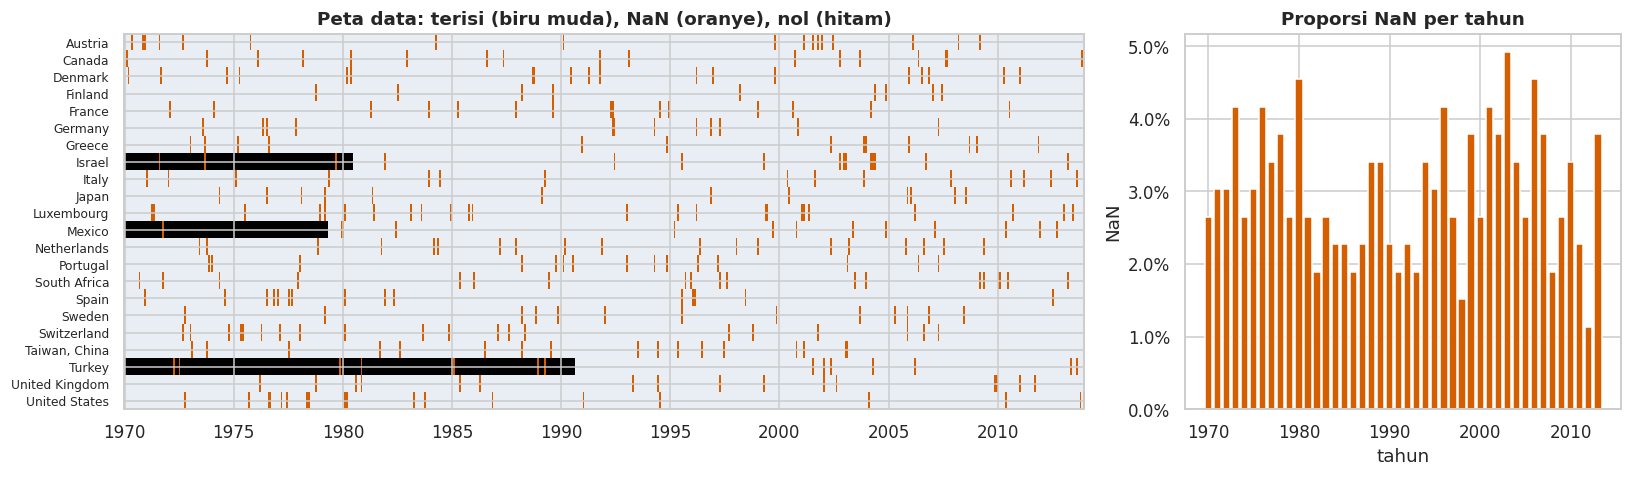

,NaN,nilai 0,nilai 0 terakhir
Country,,,
Israel,15,123,Jun 1980
Mexico,13,111,Apr 1979
Turkey,14,241,Aug 1990


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
status = np.where(panel_raw.isna(), 1, np.where(panel_raw == 0, 2, 0)).T
cmap = plt.matplotlib.colors.ListedColormap(["#E8EEF4", C2, "#000000"])
ax[0].imshow(status, aspect="auto", cmap=cmap, interpolation="nearest")
yrs = np.arange(1970, 2014, 5)
ax[0].set_xticks([(y - 1970) * 12 for y in yrs]); ax[0].set_xticklabels(yrs)
ax[0].set_yticks(range(len(panel_raw.columns))); ax[0].set_yticklabels(panel_raw.columns, fontsize=8)
ax[0].set_title("Peta data: terisi (biru muda), NaN (oranye), nol (hitam)")
nan_by_year = panel_raw.isna().groupby(panel_raw.index // 12).mean().mean(1)
ax[1].bar(nan_by_year.index, nan_by_year.values, color=C2)
pct_axis(ax[1]); ax[1].set(title="Proporsi NaN per tahun", xlabel="tahun", ylabel="NaN")
save_fig(FIG_DIR, "01_missing_map")
missing[missing["nilai 0"] > 0]

**Temuan.** Ada dua jenis data hilang dengan arti yang berbeda. **Nilai 0** hanya muncul di Israel (sampai Juni 1980), Meksiko (sampai April 1979), dan Turki (sampai Agustus 1990) sebagai blok utuh di awal seri: ini bukan harga nol, melainkan seri yang belum dicatat. **NaN** (348 sel, sekitar 3%) tersebar acak tanpa pola waktu, dengan proporsi per tahun stabil di 1 sampai 5%. Karena acak dan pendek, NaN aman diisi interpolasi, sedangkan nilai 0 harus dibuang agar tidak dianggap sebagai harga sungguhan.

### 3.2 Seperti apa perjalanan indeks di setiap negara?

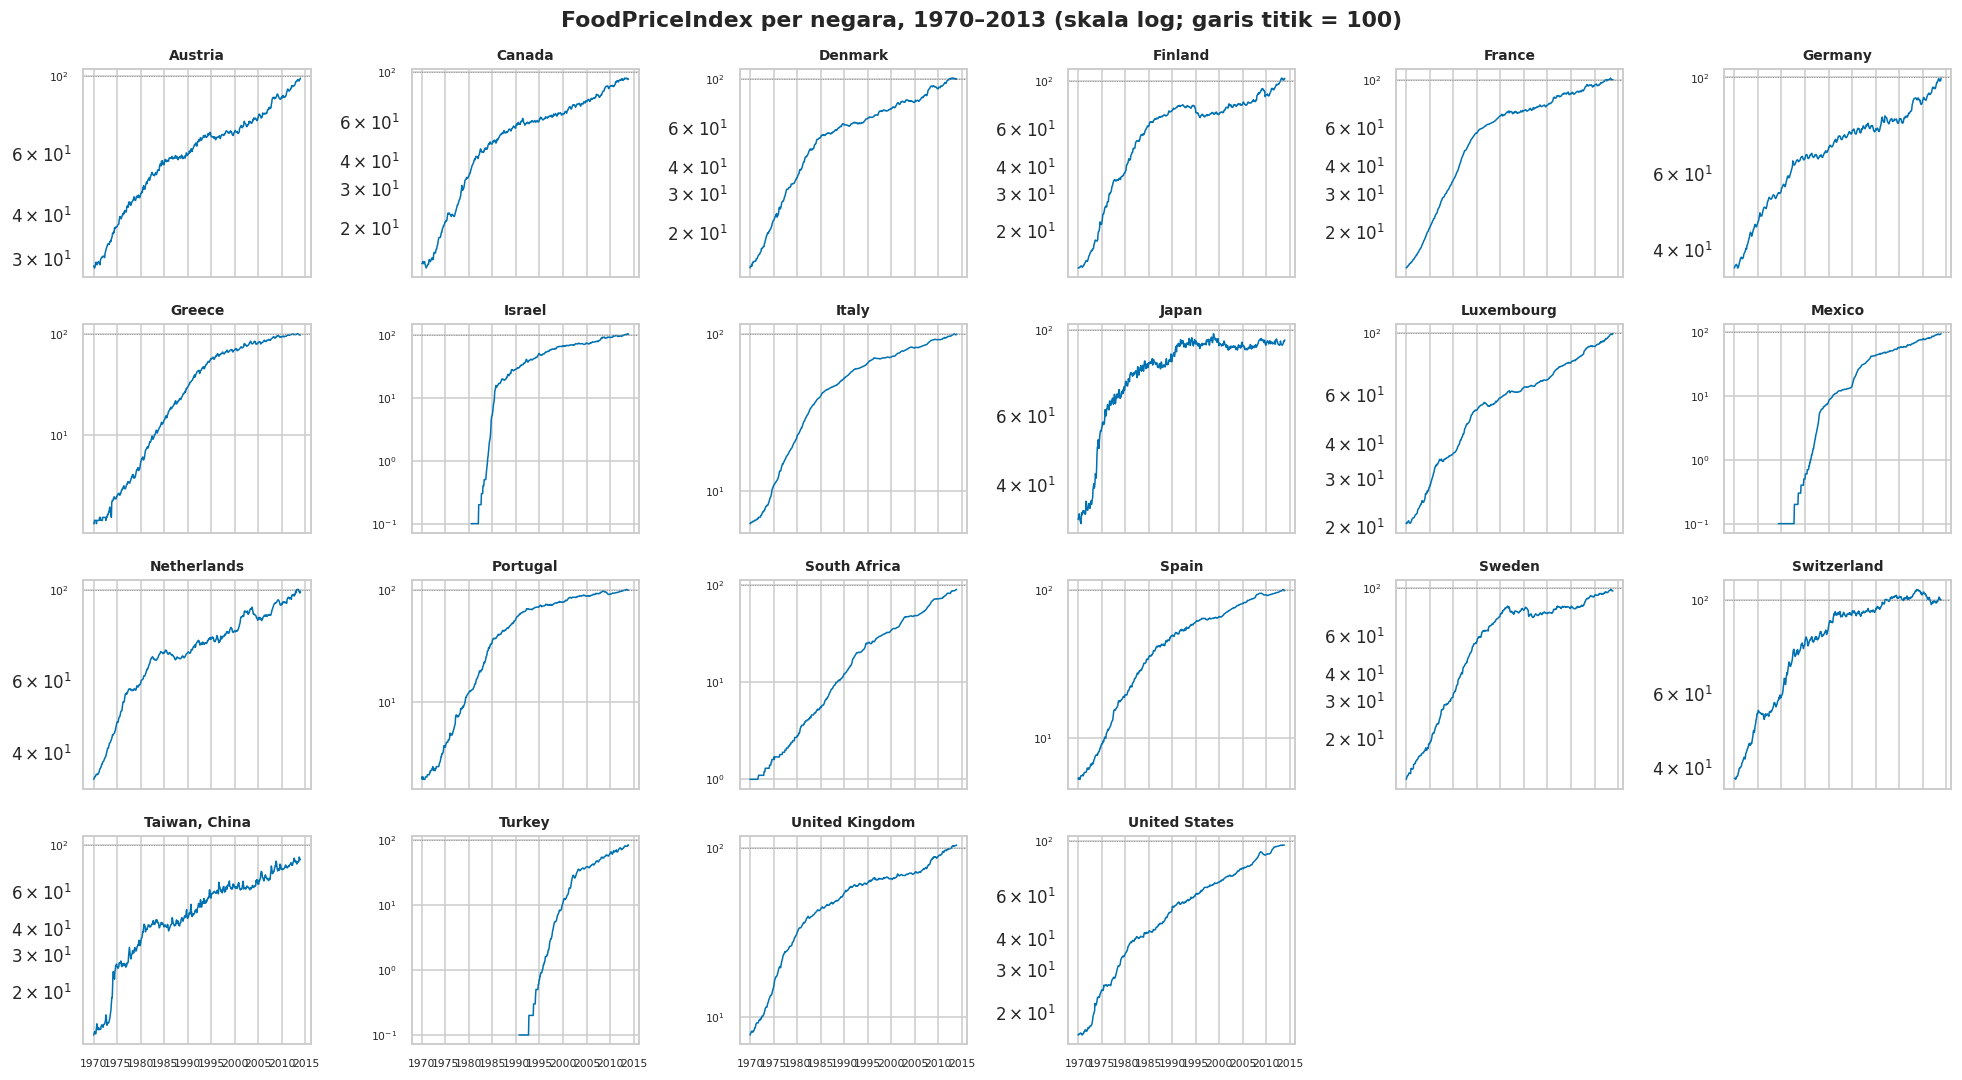

In [6]:
y = clean_panel(panel_raw)
dates = t_to_date(y.index)
fig, axes = plt.subplots(4, 6, figsize=(18, 10), sharex=True)
for ax, c in zip(axes.flat, y.columns):
    ax.semilogy(dates, y[c], color=C1, lw=1)
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=7)
    ax.axhline(100, color=CN, lw=0.6, ls=":")
for ax in axes.flat[len(y.columns):]:
    ax.axis("off")
fig.suptitle("FoodPriceIndex per negara, 1970–2013 (skala log; garis titik = 100)", fontweight="bold")
save_fig(FIG_DIR, "02_series_grid")

In [7]:
level_2013 = y[y.index >= 2013 * 12].mean().sort_values()
level_2013.round(1).to_frame("rata-rata 2013").T

Country,Turkey,"Taiwan, China",South Africa,Mexico,Japan,Canada,United States,Austria,Sweden,Germany,...,Spain,Netherlands,Denmark,Switzerland,Greece,Portugal,France,Israel,Finland,United Kingdom
rata-rata 2013,80.1,84.0,88.2,91.8,92.5,93.6,96.3,97.3,97.4,98.4,...,99.2,99.4,99.9,99.9,99.9,100.3,100.4,101.4,101.8,102.8


**Temuan.** Semua negara memakai tahun dasar yang sama: indeks berkisar di **80 sampai 103 pada 2013** (median sekitar 99), sehingga skalanya sebanding antar negara. Bentuk perjalanannya yang berbeda. Turki, Meksiko, Israel, Yunani, Portugal, dan Afrika Selatan naik dari angka 1 sampai 2 di 1970-an (hiperinflasi), sementara Jepang dan Swiss nyaris datar sejak 1990-an. Pada skala log, sebagian besar seri berbentuk garis yang makin landai, tanda bahwa pertumbuhan bersifat **multiplikatif dan melambat**.

### 3.3 Apakah laju kenaikan harga stabil dari dekade ke dekade?

Laju pertumbuhan tahunan dihitung dari rata-rata indeks per tahun, lalu dirata-rata per dekade.

In [8]:
annual = y.groupby(y.index // 12).mean()
growth = annual.pct_change() * 100
decade = growth.groupby((growth.index // 10) * 10).median().T
decade.columns = [f"{d}-an" for d in decade.columns]

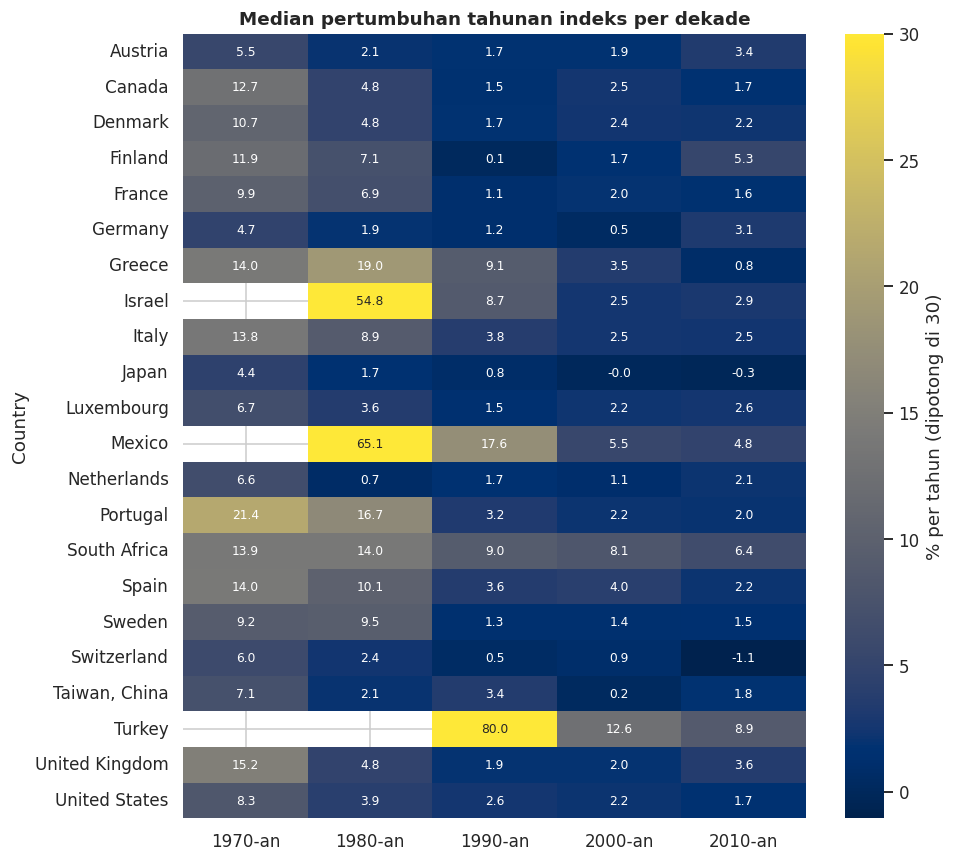

In [9]:
plt.figure(figsize=(9, 8))
sns.heatmap(decade.clip(upper=30), annot=decade.round(1), fmt="", cmap="cividis", cbar_kws={"label": "% per tahun (dipotong di 30)"},
            annot_kws={"size": 8})
plt.title("Median pertumbuhan tahunan indeks per dekade")
save_fig(FIG_DIR, "03_growth_by_decade")

**Temuan.** Laju kenaikan turun drastis: median lintas negara **9,9% per tahun di 1970-an, 4,8% di 1980-an, lalu sekitar 2% sejak 1990-an**. Negara hiperinflasi (Turki 80% di 1990-an, Meksiko 65% dan Israel 55% di 1980-an) juga konvergen ke kisaran 3 sampai 9% di 2010-an. Implikasinya, model yang belajar dari seluruh 44 tahun akan meramal kenaikan yang jauh terlalu tinggi. Hanya data beberapa tahun terakhir yang relevan untuk 2014–2023.

### 3.4 Apakah ada pola musiman?

Untuk melihat musiman, setiap nilai dibandingkan dengan rata-rata bergerak 12 bulan di sekitarnya. Rata-rata deviasi
per bulan kalender menunjukkan pola yang berulang setiap tahun.

In [10]:
recent = np.log(y[y.index >= 1995 * 12])
dev = (recent - recent.rolling(12, center=True).mean()) * 100
seas = dev.groupby(dev.index % 12 + 1).mean()

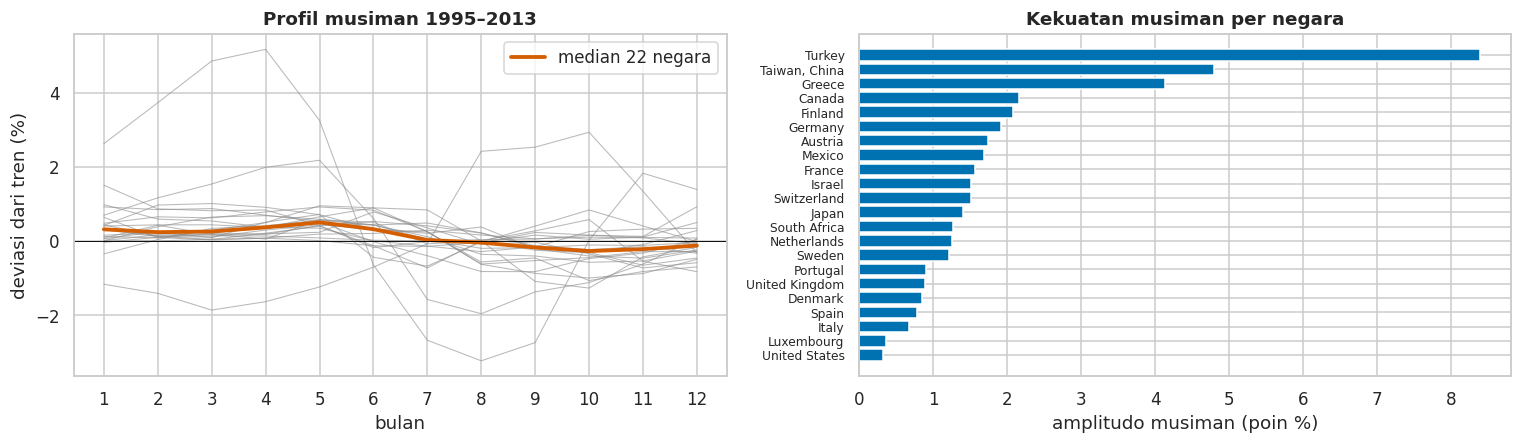

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for c in seas.columns:
    ax[0].plot(seas.index, seas[c], color=CN, lw=0.7, alpha=0.6)
ax[0].plot(seas.index, seas.median(1), color=C2, lw=2.5, label="median 22 negara")
ax[0].axhline(0, color="black", lw=0.6)
ax[0].set(xticks=range(1, 13), xlabel="bulan", ylabel="deviasi dari tren (%)", title="Profil musiman 1995–2013"); ax[0].legend()
amp = (seas.max() - seas.min()).sort_values()
ax[1].barh(amp.index, amp.values, color=C1)
ax[1].set(xlabel="amplitudo musiman (poin %)", title="Kekuatan musiman per negara")
ax[1].tick_params(axis="y", labelsize=8)
save_fig(FIG_DIR, "04_seasonality")

**Temuan.** Pola musiman ada tetapi kecil. Median profilnya hanya naik sekitar 0,5% di bulan Mei dan turun 0,3% di bulan Oktober. Amplitudo terbesar ada di Turki (8,4 poin), Taiwan (4,8), dan Yunani (4,1), sementara Amerika Serikat dan Luksemburg hampir tanpa musiman (di bawah 0,4). Dibandingkan pertumbuhan 2% per tahun yang terakumulasi menjadi 20% dalam 10 tahun, musiman adalah detail. Komponen musiman tetap diuji karena bisa membantu negara seperti Turki dan Taiwan.

### 3.5 Apakah negara-negara bergerak bersama?

Jika pertumbuhan harga pangan di satu negara mirip dengan negara lain, informasi lintas negara bisa dipakai untuk
menstabilkan ramalan. Diukur dengan korelasi pertumbuhan tahunan antar negara pada periode 1995–2013.

In [12]:
g_recent = growth.loc[1995:2013]
corr = g_recent.corr()
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).stack()
common = g_recent.median(1)

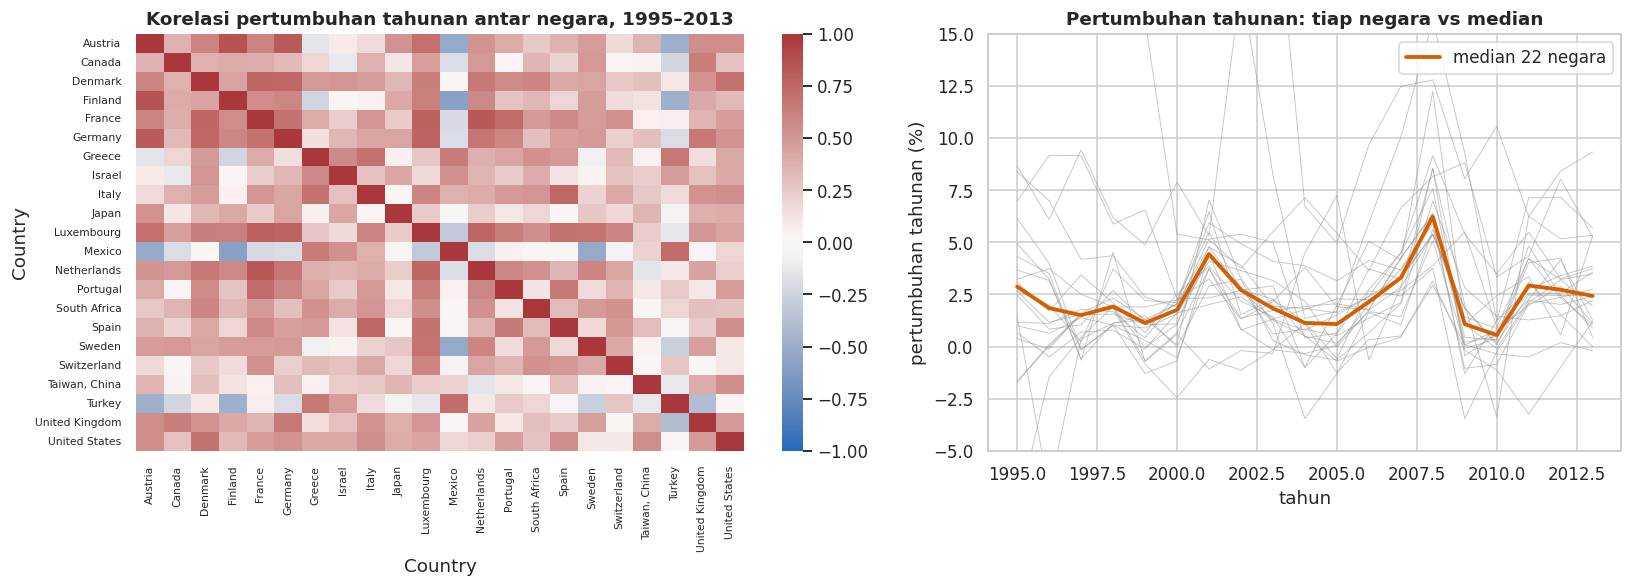

Median korelasi antar pasangan negara: 0.35


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax[0], xticklabels=True, yticklabels=True)
ax[0].tick_params(labelsize=7); ax[0].set_title("Korelasi pertumbuhan tahunan antar negara, 1995–2013")
for c in g_recent.columns:
    ax[1].plot(g_recent.index, g_recent[c], color=CN, lw=0.6, alpha=0.5)
ax[1].plot(common.index, common.values, color=C2, lw=2.5, label="median 22 negara")
ax[1].set(ylim=(-5, 15), xlabel="tahun", ylabel="pertumbuhan tahunan (%)", title="Pertumbuhan tahunan: tiap negara vs median")
ax[1].legend()
save_fig(FIG_DIR, "05_comovement")
print(f"Median korelasi antar pasangan negara: {off_diag.median():.2f}")

**Temuan.** Median korelasi pertumbuhan tahunan antar pasangan negara adalah **0,35**: positif tetapi jauh dari sempurna. Grafik kanan memperlihatkan median 22 negara bergerak di kisaran 1 sampai 3% per tahun dengan lonjakan bersama di 2008 (6,2%, krisis harga pangan dunia). Artinya ada **tren global bersama** yang jauh lebih stabil daripada seri satu negara. Ini dasar untuk model gabungan di bagian 8.

## 4. Preprocessing

| Temuan EDA | Keputusan |
| --- | --- |
| Nilai 0 menandai seri yang belum dimulai (3.1) | 0 diubah menjadi NaN dan tidak dipakai untuk melatih maupun mengevaluasi |
| NaN tersebar acak di tengah seri (3.1) | diisi interpolasi linear untuk melatih; tidak diisi saat mengevaluasi |
| Pertumbuhan bersifat multiplikatif dan berbeda jauh antar era (3.2, 3.3) | model bekerja pada skala log, dan hanya memakai 3–15 tahun terakhir |
| Musiman kecil tetapi ada (3.4) | diuji sebagai komponen opsional |
| Negara bergerak bersama (3.5) | diuji model yang meminjam laju pertumbuhan dari negara lain |

In [14]:
panel = clean_panel(panel_raw)
print("NaN tersisa setelah interpolasi (hanya awal seri yang belum dimulai):", int(panel.isna().sum().sum()))

NaN tersisa setelah interpolasi (hanya awal seri yang belum dimulai): 487


## 5. Desain validasi: backtest rolling-origin

Data uji adalah 10 tahun **setelah** data latih berakhir, jadi validasi harus meniru situasi itu. K-Fold acak tidak
cocok karena akan memakai masa depan untuk meramal masa lalu. Digunakan **tiga backtest**: model dilatih dengan data
sampai akhir 1993, 1998, dan 2003, lalu meramal 120 bulan berikutnya. Skor akhir adalah rata-rata SMAPE ketiganya.

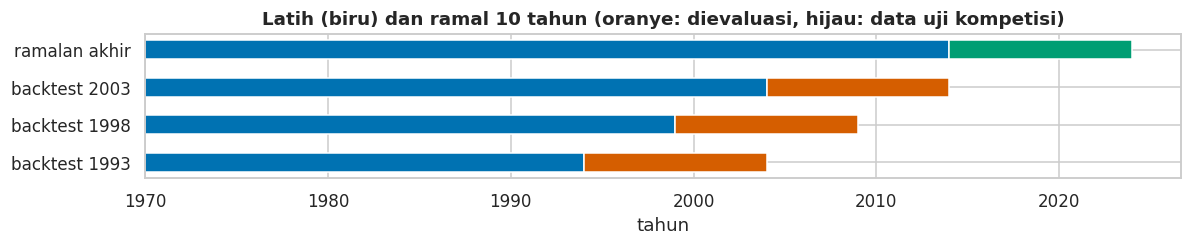

In [15]:
fig, ax = plt.subplots(figsize=(11, 2.4))
for i, o in enumerate(ORIGINS + [2013]):
    ax.barh(i, (o + 1) - 1970, left=1970, color=C1, height=0.5)
    ax.barh(i, 10, left=o + 1, color=C2 if o != 2013 else C3, height=0.5)
ax.set_yticks(range(len(ORIGINS) + 1)); ax.set_yticklabels([f"backtest {o}" for o in ORIGINS] + ["ramalan akhir"])
ax.set(xlabel="tahun", title="Latih (biru) dan ramal 10 tahun (oranye: dievaluasi, hijau: data uji kompetisi)")
save_fig(FIG_DIR, "06_backtest_design")

## 6. Baseline

Dua baseline paling sederhana: **nilai terakhir** dan **rata-rata 12 bulan terakhir**, yaitu menganggap harga
tidak berubah selama 10 tahun.

In [16]:
MODELS = {"nilai terakhir": fc_last, "rata-rata 12 bulan": fc_mean12}
bt_base = backtest(panel, panel_raw, MODELS, ORIGINS, HORIZON)
bt_base.pivot_table(index="model", columns="origin", values="smape").assign(rata_rata=lambda d: d.mean(1)).style.format("{:.2f}")

origin,1993,1998,2003,rata_rata
model,,,,
nilai terakhir,11.36,12.21,12.59,12.05
rata-rata 12 bulan,12.39,13.21,13.26,12.95


**Temuan.** Menganggap harga tidak berubah selama 10 tahun menghasilkan SMAPE **12,05** (nilai terakhir) dan **12,95** (rata-rata 12 bulan). Skornya stabil di ketiga backtest, yang memperlihatkan bahwa kesalahan utamanya sistematis: harga hampir selalu naik, dan baseline melewatkan seluruh kenaikan itu. Rata-rata 12 bulan sedikit lebih buruk karena titik awalnya sudah tertinggal setengah tahun dari tren.

## 7. Model per negara

Tiga keluarga model, masing-masing dilatih terpisah untuk setiap negara pada skala log:

- **Drift**: melanjutkan tren log linear dari 3, 5, atau 10 tahun terakhir.
- **Damped trend (Holt)**: tren yang melemah perlahan, cocok untuk horizon panjang.
- **Damped trend + musiman**: sama, dengan komponen musiman 12 bulan (dari temuan 3.4).

In [17]:
MODELS_LOCAL = {
    "drift 3 tahun": make_drift(3), "drift 5 tahun": make_drift(5), "drift 10 tahun": make_drift(10),
    "damped trend": fc_damped, "damped trend + musiman": fc_damped_seasonal,
}
bt_local = backtest(panel, panel_raw, MODELS_LOCAL, ORIGINS, HORIZON)
bt_local.pivot_table(index="model", columns="origin", values="smape").assign(rata_rata=lambda d: d.mean(1)) \
    .sort_values("rata_rata").style.format("{:.2f}").highlight_min(subset=["rata_rata"], color="#CDE7F0")

origin,1993,1998,2003,rata_rata
model,,,,
damped trend + musiman,6.17,8.53,8.53,7.75
damped trend,6.43,8.64,8.95,8.01
drift 3 tahun,9.00,8.27,8.45,8.57
drift 5 tahun,11.94,11.12,8.01,10.35
drift 10 tahun,13.69,11.88,8.26,11.28


**Temuan.** Damped trend + musiman adalah model per negara terbaik (**7,75**), disusul damped trend (8,01) dan drift 3 tahun (8,57). Drift dengan jendela panjang lebih buruk (5 tahun 10,35; 10 tahun 11,28) dan sangat buruk di backtest 1993, ketika jendela 10 tahun masih memuat inflasi tinggi 1980-an. Ini mengonfirmasi temuan 3.3: **jendela pendek dan tren yang melemah** lebih cocok untuk horizon panjang.

## 8. Model gabungan lintas negara

Temuan 3.5 menunjukkan negara-negara bergerak bersama. Laju pertumbuhan satu negara yang diestimasi dari 5 tahun
saja rentan noise, sehingga laju itu **disusutkan** ke median laju semua negara:

$$g_{\text{akhir}} = (1-w)\cdot g_{\text{negara}} + w\cdot g_{\text{median}}$$

$w = 0$ berarti setiap negara berdiri sendiri, $w = 1$ berarti semua negara memakai laju yang sama.
Median dihitung hanya dari data sebelum origin, jadi tidak ada kebocoran.

In [18]:
MODELS_POOL = {f"pooled w={w:.2f}": make_pooled_drift(w) for w in POOL_WEIGHTS}
bt_pool = backtest(panel, panel_raw, MODELS_POOL, ORIGINS, HORIZON)
pool_tab = bt_pool.groupby("model").smape.mean()
pool_tab.to_frame("SMAPE rata-rata").T.style.format("{:.2f}")

model,pooled w=0.00,pooled w=0.25,pooled w=0.50,pooled w=0.75,pooled w=1.00
SMAPE rata-rata,10.30,8.34,6.68,6.07,7.45


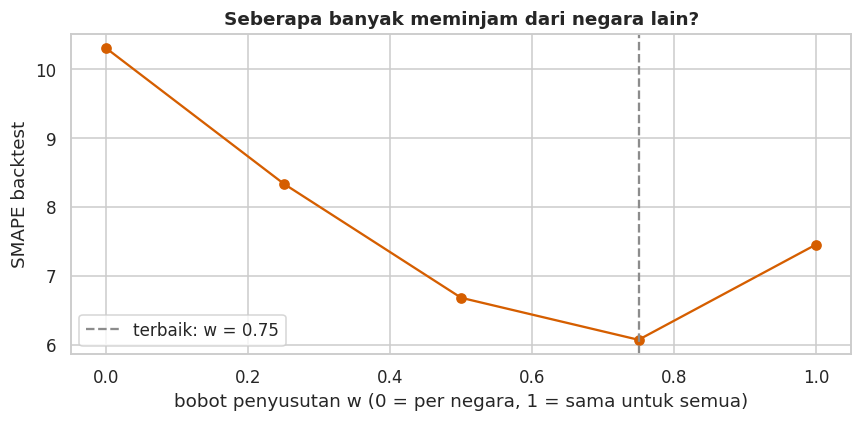

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(POOL_WEIGHTS, pool_tab.values, marker="o", color=C2)
best_w = POOL_WEIGHTS[int(np.argmin(pool_tab.values))]
ax.axvline(best_w, color=CN, ls="--", label=f"terbaik: w = {best_w}")
ax.set(xlabel="bobot penyusutan w (0 = per negara, 1 = sama untuk semua)", ylabel="SMAPE backtest", title="Seberapa banyak meminjam dari negara lain?")
ax.legend()
save_fig(FIG_DIR, "07_pooling_weight")

**Temuan.** Kurvanya berbentuk U yang jelas. Setiap negara sendiri ($w = 0$) memberi SMAPE **10,30**, sedangkan $w = 0,75$ menurunkannya menjadi **6,07**, lebih baik dari semua model per negara. Memaksakan laju yang sama untuk semua negara ($w = 1$, SMAPE 7,45) kembali memburuk karena perbedaan nyata antar negara ikut terhapus. Jawaban atas pertanyaan penelitian: **pinjam sebagian besar, tetapi tidak semuanya**. Satu catatan: Turki baru punya data sejak 1990, sehingga tidak memenuhi syarat minimal 15 tahun riwayat dan tidak ikut dievaluasi di backtest.

### 8.1 Ensemble

Model gabungan (tren yang distabilkan) dan damped trend + musiman (menangkap pola musiman dan pelemahan tren)
membuat kesalahan yang berbeda, sehingga rata-rata keduanya diuji sebagai model akhir.

In [20]:
POOL_BEST = make_pooled_drift(best_w)
MODELS_ENS = {
    "ensemble: pooled + damped musiman": make_ensemble(POOL_BEST, fc_damped_seasonal),
    "ensemble: pooled + damped": make_ensemble(POOL_BEST, fc_damped),
    "ensemble: pooled + damped musiman + drift 3 tahun": make_ensemble(POOL_BEST, fc_damped_seasonal, make_drift(3)),
}
bt_ens = backtest(panel, panel_raw, MODELS_ENS, ORIGINS, HORIZON)
bt_all = pd.concat([bt_base, bt_local, bt_pool[bt_pool.model == f"pooled w={best_w:.2f}"], bt_ens])
leader = bt_all.pivot_table(index="model", columns="origin", values="smape").assign(rata_rata=lambda d: d.mean(1)).sort_values("rata_rata")
leader.style.format("{:.2f}").background_gradient(subset=["rata_rata"], cmap="cividis_r")

origin,1993,1998,2003,rata_rata
model,,,,
ensemble: pooled + damped musiman,4.69,6.16,6.04,5.63
ensemble: pooled + damped,4.78,6.21,6.03,5.67
ensemble: pooled + damped musiman + drift 3 tahun,5.18,6.52,5.59,5.77
pooled w=0.75,7.29,4.88,6.16,6.11
damped trend + musiman,6.17,8.53,8.53,7.75
damped trend,6.43,8.64,8.95,8.01
drift 3 tahun,9.00,8.27,8.45,8.57
drift 5 tahun,11.94,11.12,8.01,10.35
drift 10 tahun,13.69,11.88,8.26,11.28


**Temuan.** Rata-rata tren gabungan dengan damped trend + musiman adalah yang terbaik (**5,63**), sedikit di atas versi tanpa musiman (5,67). Keduanya saling menutupi: model gabungan unggul di backtest 1998 (4,88), sedangkan ensemble jauh lebih stabil di tiga backtest (4,69 / 6,16 / 6,04) dibanding model gabungan sendiri (7,29 / 4,88 / 6,16). Menambahkan drift 3 tahun justru memperburuk rata-rata (5,77). **Catatan jalan buntu**: drift 10 tahun dan rata-rata 12 bulan tidak pernah lebih baik dari baseline sederhana yang lebih cepat dihitung, sehingga tidak dipakai lagi.

## 9. Evaluasi

### 9.1 Bagaimana error berkembang sepanjang horizon?

In [21]:
FINAL_NAME = leader.index[0]
show = [FINAL_NAME, f"pooled w={best_w:.2f}", "damped trend + musiman", "drift 5 tahun", "nilai terakhir"]
by_year = (bt_all[bt_all.model.isin(show)]
           .assign(y=lambda d: d.smape_by_year.apply(pd.Series).values.tolist())
           .pipe(lambda d: pd.DataFrame([{"model": m, "tahun ke-": k + 1, "smape": v}
                                          for m, yrs in zip(d.model, d.smape_by_year) for k, v in yrs.items()]))
           .groupby(["model", "tahun ke-"]).smape.mean().unstack(0))

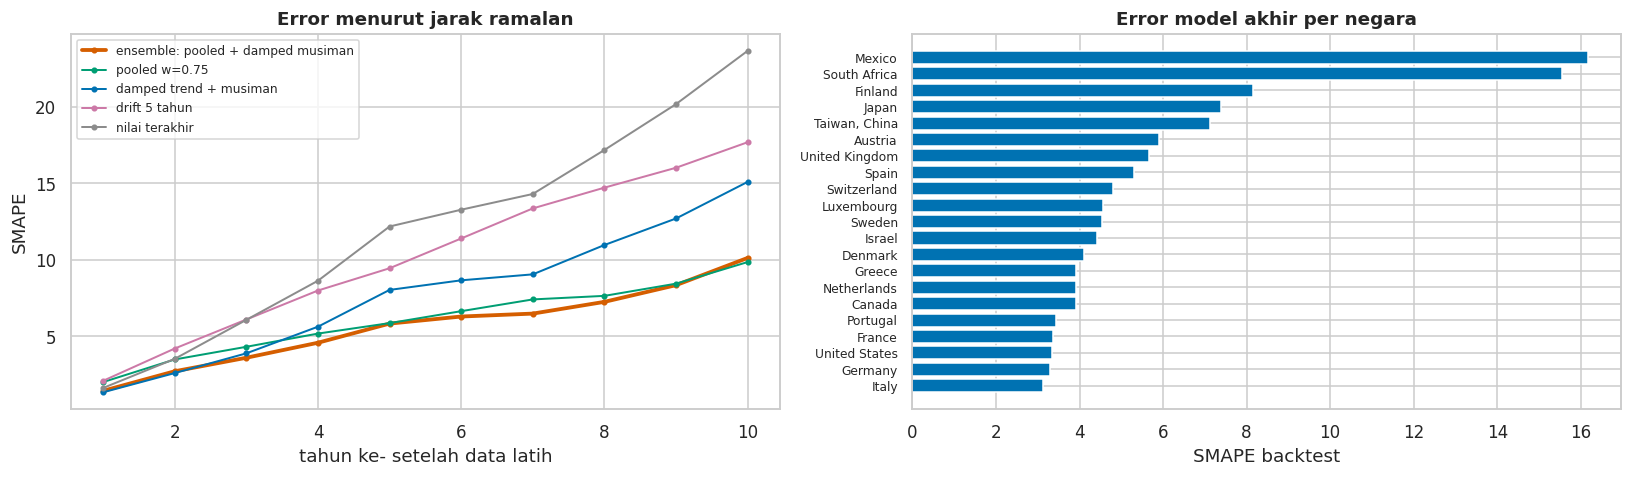

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
colors = [C2, C3, C1, "#CC79A7", CN]
for m, col in zip(show, colors):
    ax[0].plot(by_year.index, by_year[m], marker="o", ms=3, label=m, color=col, lw=2.5 if m == FINAL_NAME else 1.3)
ax[0].set(xlabel="tahun ke- setelah data latih", ylabel="SMAPE", title="Error menurut jarak ramalan"); ax[0].legend(fontsize=8)
per_c = bt_all[bt_all.model == FINAL_NAME].groupby("country").smape.mean().sort_values()
ax[1].barh(per_c.index, per_c.values, color=C1); ax[1].tick_params(axis="y", labelsize=8)
ax[1].set(xlabel="SMAPE backtest", title="Error model akhir per negara")
save_fig(FIG_DIR, "08_error_by_horizon")

**Temuan.** Error semua model membesar seiring jarak ramalan, tetapi lajunya berbeda. Di tahun pertama semua model setara (SMAPE 1,3 sampai 2,1). Di tahun kesepuluh, baseline nilai terakhir mencapai **23,7**, damped trend + musiman 15,1, dan model akhir **10,1**. Per negara, error model akhir di bawah 6 untuk 16 dari 21 negara yang dievaluasi. Meksiko (16,2) dan Afrika Selatan (15,6) paling sulit karena inflasinya berubah rezim di tengah horizon.

### 9.2 Contoh ramalan backtest: apa yang terlihat di lapangan?

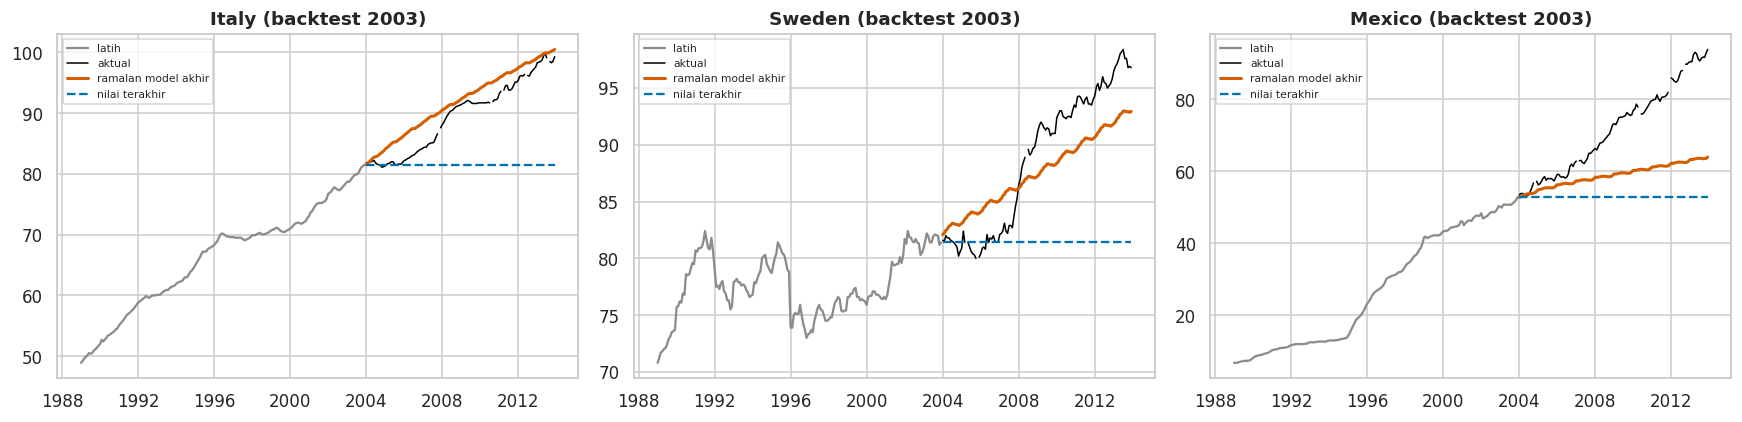

In [23]:
cut = (ORIGINS[-1] + 1) * 12
ctx = context(panel, cut)
examples = [per_c.index[0], per_c.index[len(per_c) // 2], per_c.index[-1]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, examples):
    s = ctx["hist"][c]; idx = range(cut, cut + HORIZON)
    ax.plot(t_to_date(s.index[-180:]), s.iloc[-180:], color=CN, label="latih")
    act = panel_raw[c].reindex(idx).replace(0, np.nan)
    ax.plot(t_to_date(list(idx)), act.values, color="black", lw=1, label="aktual")
    ax.plot(t_to_date(list(idx)), MODELS_ENS[FINAL_NAME](s, HORIZON, ctx) if FINAL_NAME in MODELS_ENS else POOL_BEST(s, HORIZON, ctx),
            color=C2, lw=2, label="ramalan model akhir")
    ax.plot(t_to_date(list(idx)), fc_last(s, HORIZON), color=C1, ls="--", label="nilai terakhir")
    ax.set_title(f"{c} (backtest 2003)"); ax.legend(fontsize=7)
save_fig(FIG_DIR, "09_backtest_examples")

**Temuan.** Tiga contoh dari backtest 2003 mewakili error terendah, menengah, dan tertinggi. **Italia** diramal hampir sempurna karena trennya stabil. **Swedia** datar pada 2004–2007 lalu melonjak saat krisis 2008. Model menangkap arahnya tetapi meleset di besarannya, karena lonjakan seperti itu memang tidak bisa diramal dari data sebelum 2004. **Meksiko** adalah kegagalan yang jujur: penyusutan ke median global meredam tren Meksiko yang sebenarnya tetap tinggi. Pinjaman informasi yang menolong rata-rata justru merugikan negara yang benar-benar berbeda.

## 10. Ramalan akhir dan submission

Model akhir dilatih ulang dengan seluruh data 1970–2013, lalu meramal Januari 2014 sampai Desember 2023.

In [24]:
final_model = MODELS_ENS.get(FINAL_NAME) or {**MODELS_LOCAL, **MODELS_POOL}.get(FINAL_NAME, POOL_BEST)
cut = 2014 * 12
ctx = context(panel, cut)
fc_rows = []
for c in panel.columns:
    f = final_model(panel[c].dropna(), HORIZON, ctx)
    fc_rows += [{"Country": c, "t": cut + i, "FoodPriceIndex": v} for i, v in enumerate(f)]
forecast = pd.DataFrame(fc_rows)
sub = test.merge(forecast, on=["Country", "t"], how="left")[["id", "FoodPriceIndex"]]
assert sub.FoodPriceIndex.notna().all() and len(sub) == len(sample)
sub = sample[["id"]].merge(sub, on="id", how="left")
sub.to_csv(OUT_DIR / "submission.csv", index=False)
print("Model akhir:", FINAL_NAME)
sub.FoodPriceIndex.describe().to_frame("ramalan").T.style.format("{:.2f}")

Model akhir: ensemble: pooled + damped musiman


,count,mean,std,min,25%,50%,75%,max
ramalan,2640.00,105.94,7.47,82.33,101.48,105.83,110.52,126.85


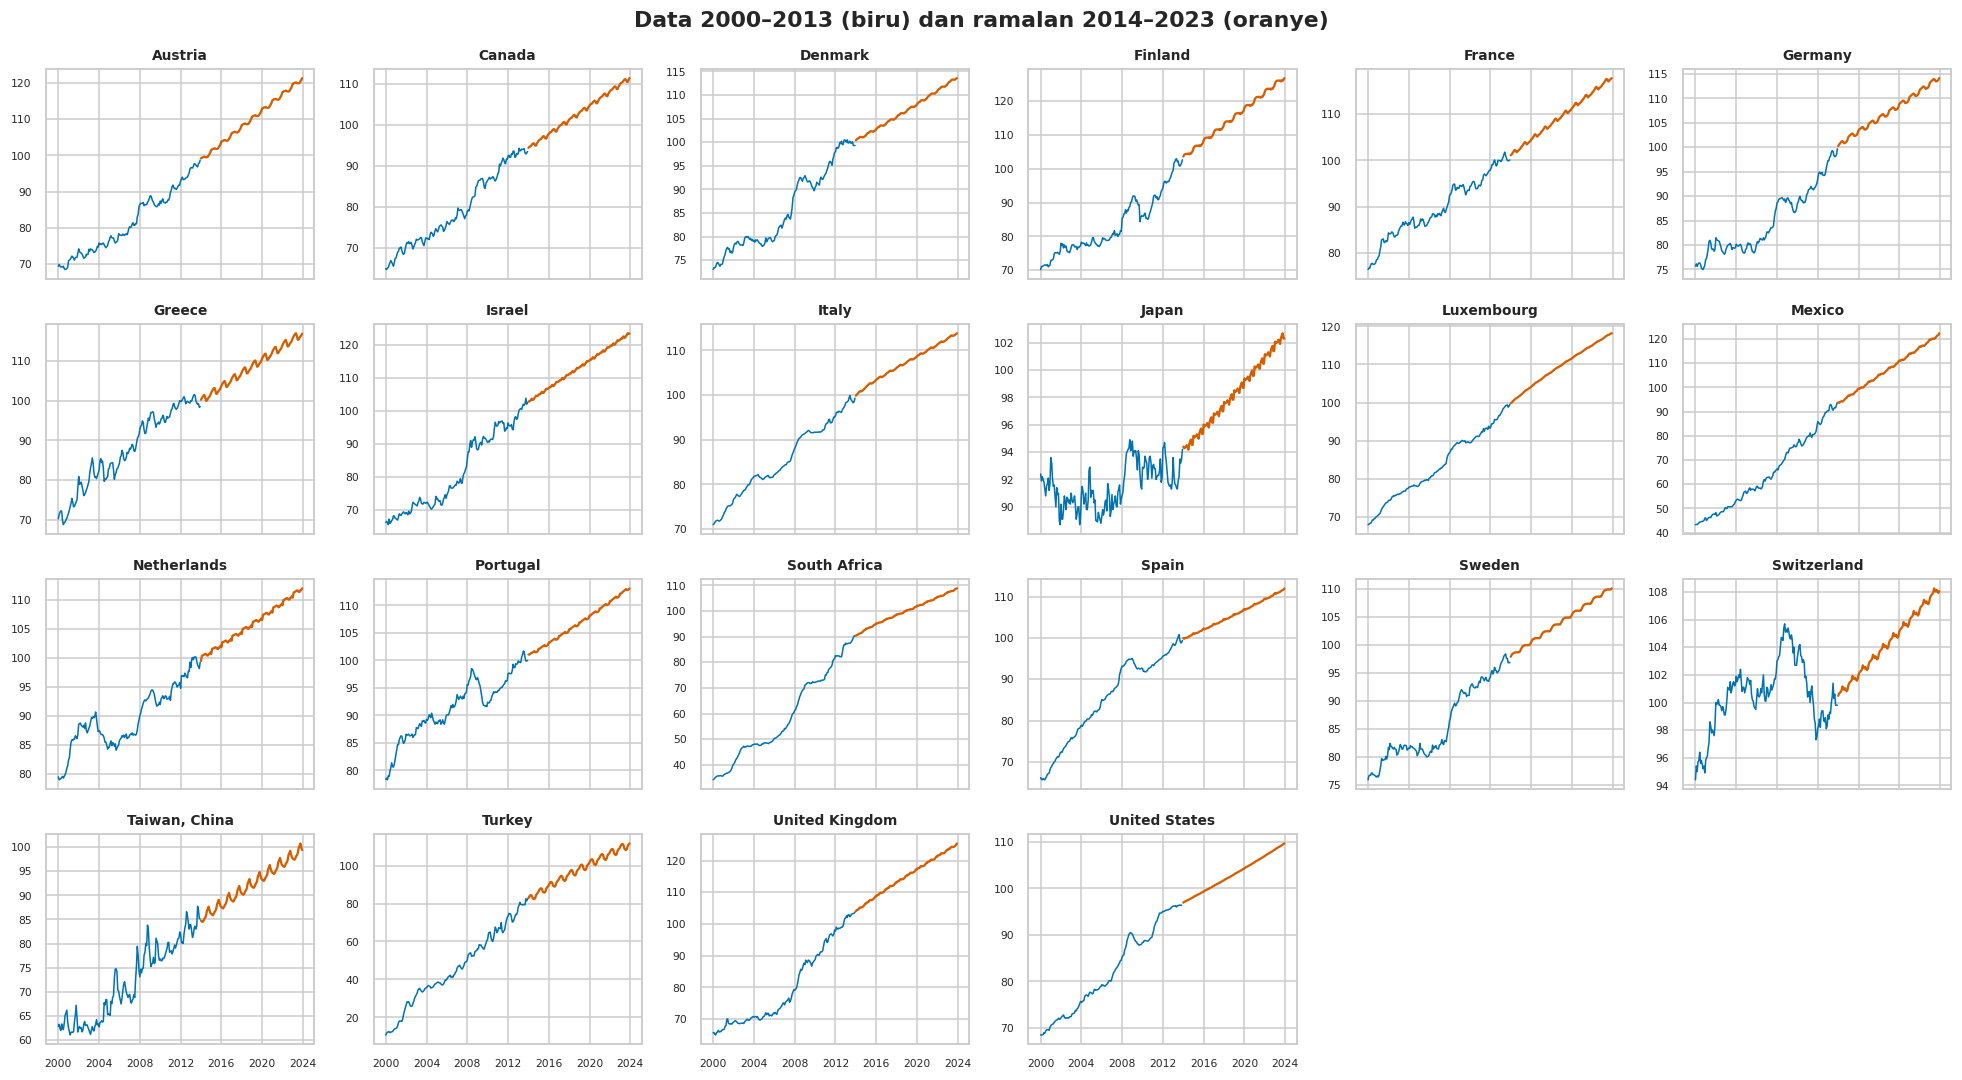

In [25]:
fc_panel = forecast.pivot(index="t", columns="Country", values="FoodPriceIndex")
fig, axes = plt.subplots(4, 6, figsize=(18, 10), sharex=True)
for ax, c in zip(axes.flat, panel.columns):
    hist = panel[c][panel.index >= 2000 * 12]
    ax.plot(t_to_date(hist.index), hist, color=C1, lw=1)
    ax.plot(t_to_date(fc_panel.index), fc_panel[c], color=C2, lw=1.5)
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=7)
for ax in axes.flat[len(panel.columns):]:
    ax.axis("off")
fig.suptitle("Data 2000–2013 (biru) dan ramalan 2014–2023 (oranye)", fontweight="bold")
save_fig(FIG_DIR, "10_final_forecast")
leader.to_csv(OUT_DIR / "backtest_leaderboard.csv")
by_year.to_csv(OUT_DIR / "smape_by_horizon_year.csv")

**Temuan.** Ramalan 2014–2023 melanjutkan tren setiap negara dengan laju yang lebih seragam. Median kenaikan sepuluh tahun sekitar **17%** (sekitar 1,6% per tahun), dari 8% di Swiss sampai 38% di Turki. Urutan antar negara tetap logis: negara dengan inflasi tinggi diramal naik paling cepat, sementara Jepang dan Swiss paling lambat. Jepang tampak naik lebih curam daripada sejarahnya karena ikut tertarik ke median global. Ini konsekuensi yang disadari dari penyusutan.

## 11. Kesimpulan

1. Untuk horizon 10 tahun, **meminjam laju pertumbuhan dari negara lain** (penyusutan 75% ke median) adalah langkah terbesar: SMAPE backtest turun dari 10,30 ke 6,07.
2. Data lama menyesatkan karena rezim inflasi sudah berubah. Jendela 3 sampai 5 tahun dan tren yang melemah lebih tepat daripada sejarah 44 tahun.
3. Model akhir (ensemble tren gabungan + damped trend musiman) mencapai SMAPE backtest **5,63**, kurang dari setengah baseline nilai terakhir.

**Skor kompetisi.** Late submission notebook ini mendapat SMAPE **3,67 (public) dan 10,99 (private)**. Skor private lebih buruk dari submission terbaik tim saat kompetisi Desember 2024 (9,86). Selisih besar antara public dan private, yang juga terlihat di seluruh leaderboard (juara private 8,93), sejalan dengan temuan 9.1 bahwa error membesar di tahun-tahun akhir horizon. Dugaan saya, bagian private memuat tahun-tahun akhir ketika inflasi pangan dunia melonjak (2021–2023), sementara model yang meredam tren justru meramal kenaikan yang lebih landai. Backtest tidak memuat guncangan sebesar itu, sehingga skor ini adalah batas nyata dari pendekatan berbasis sejarah.

**Keterbatasan.**
- Backtest hanya tiga origin, dan Turki tidak ikut dievaluasi karena riwayatnya pendek.
- Penyusutan merugikan negara yang benar-benar berbeda (Meksiko, Afrika Selatan, Jepang). Bobot per kelompok negara bisa menjadi langkah lanjut.
- Guncangan seperti krisis pangan 2008 atau inflasi pascapandemi 2021–2023 tidak bisa diramal dari data historis saja. Variabel eksternal (harga komoditas dunia, kurs) tidak tersedia di kompetisi ini.

### Jejak lingkungan

In [26]:
import platform
pkgs = ["numpy", "pandas", "statsmodels", "matplotlib", "seaborn"]
print(" | ".join([f"python {platform.python_version()}"] + [f"{p} {version(p)}" for p in pkgs]))
print(f"Waktu eksekusi total: {(time.time() - T0) / 60:.1f} menit")

python 3.13.18 | numpy 2.1.3 | pandas 2.3.3 | statsmodels 0.15.0 | matplotlib 3.10.0 | seaborn 0.13.2
Waktu eksekusi total: 1.2 menit
